# COU07506 - Digital Signal Processing

## Week 4: z-Transform Laboratory

**Registration Number:** 240242444701

**Laboratory:** Poles, Zeros and Stability

## Pre-Lab Questions

### Question 1(a)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p

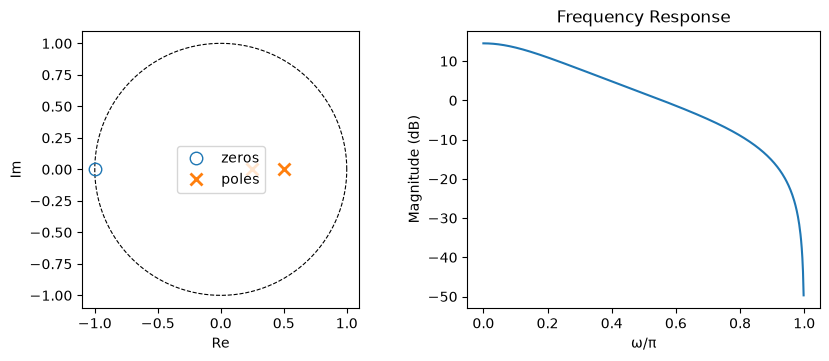

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [3]:
b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")

plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

In [4]:
r, p, k = signal.residuez(
    [1],
    [1, -0.75, 0.125]
)

print("Residues:", r)
print("Poles:", p)

n = np.arange(10)

x_pf = sum(
    ri * pi**n
    for ri, pi in zip(r, p)
).real

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(
    [1],
    [1, -0.75, 0.125],
    impulse
)

print("Inverse Z-transform:", x_pf)
print("Using lfilter:", x_lf)

print("Results match:", np.allclose(x_pf, x_lf))

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Inverse Z-transform: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Using lfilter: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Results match: True


In [5]:
r, p, k = signal.residuez(
    [1, 1],
    [1, -0.75, 0.125]
)

print("Residues:", r)
print("Poles:", p)

n = np.arange(10)

h_pf = sum(
    ri * pi**n
    for ri, pi in zip(r, p)
).real

impulse = np.zeros(10)
impulse[0] = 1

h_lf = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Impulse response using residuez:", h_pf)
print("Impulse response using lfilter:", h_lf)

print("Results match:", np.allclose(h_pf, h_lf))

Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Impulse response using residuez: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Impulse response using lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


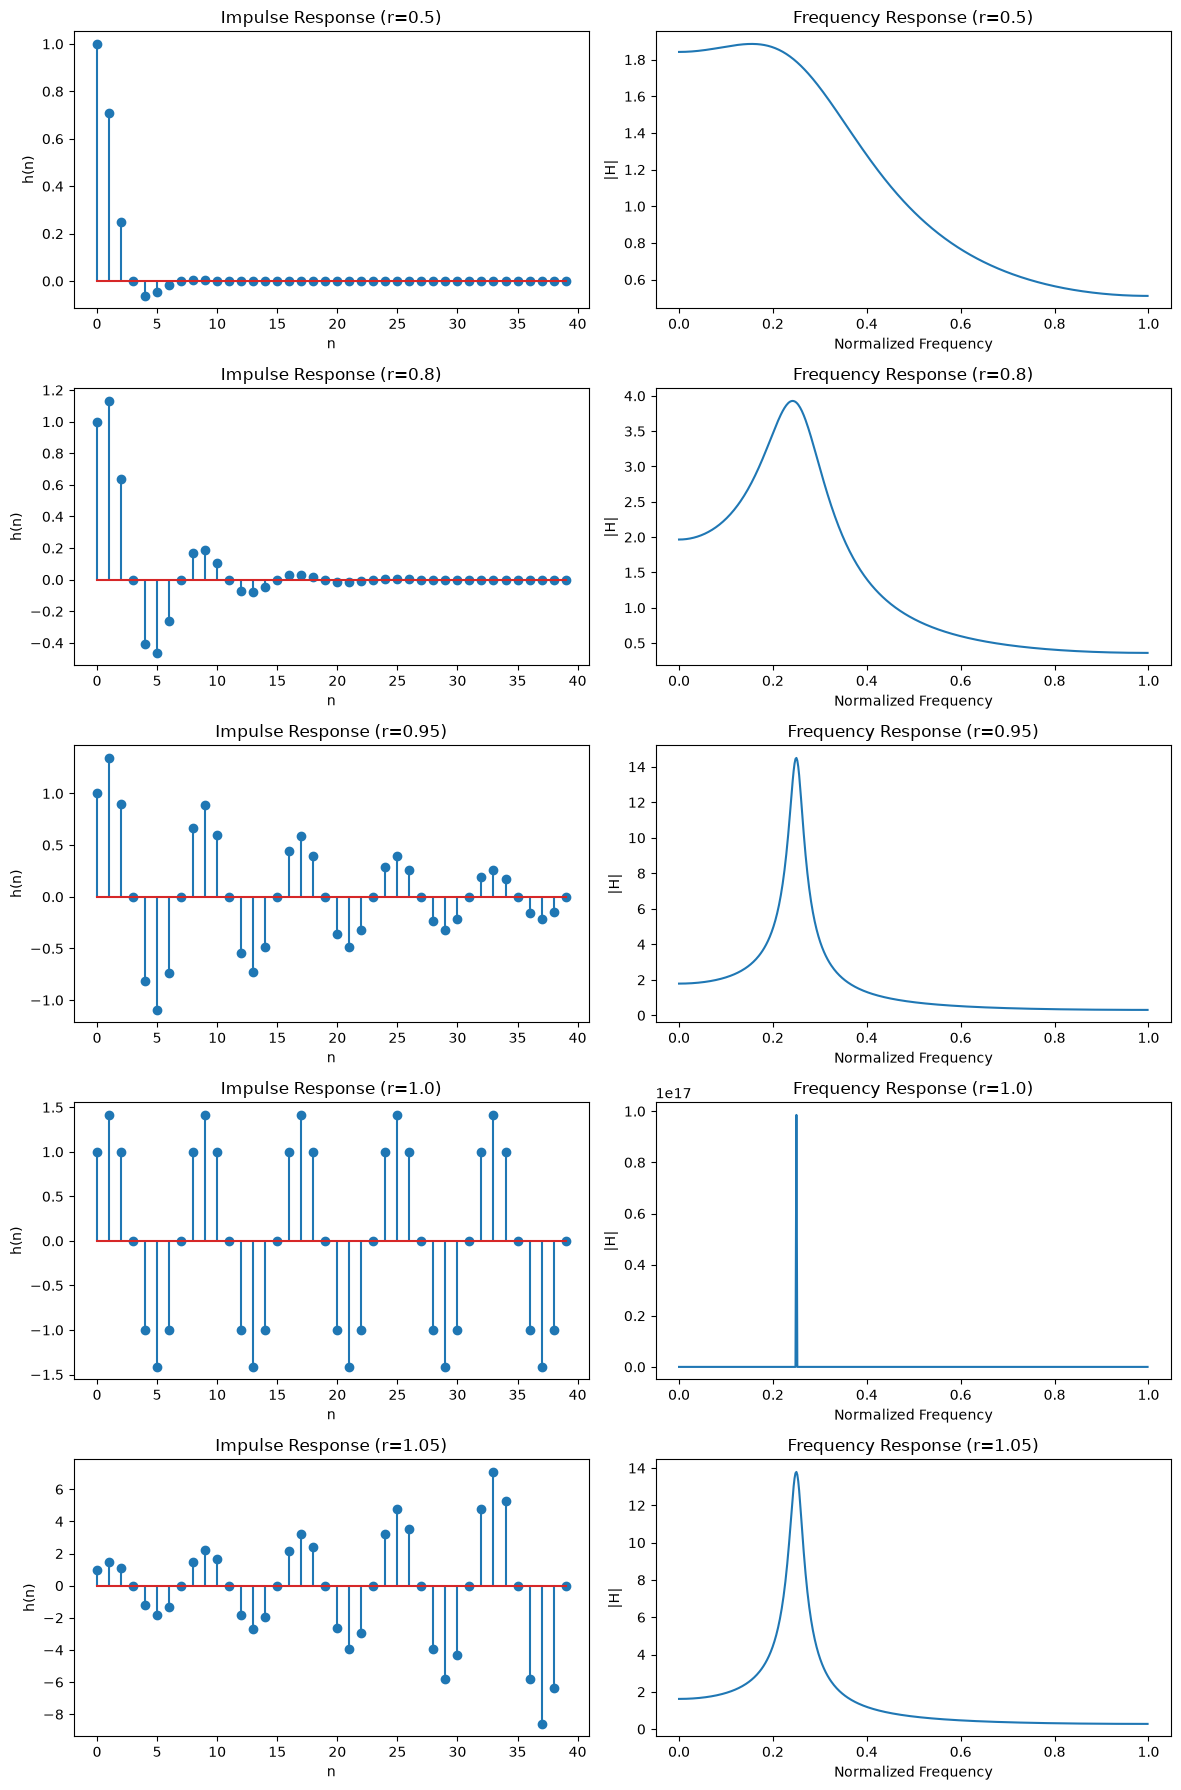

In [6]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

fig, axes = plt.subplots(5, 2, figsize=(12, 18))

for i, r in enumerate(r_values):

    a = [
        1,
        -2*r*np.cos(np.pi/4),
        r**2
    ]

    b = [1]

    h = signal.lfilter(b, a, impulse)

    w, H = signal.freqz(b, a, worN=512)

    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse Response (r={r})")
    axes[i, 0].set_xlabel("n")
    axes[i, 0].set_ylabel("h(n)")

    axes[i, 1].plot(w/np.pi, np.abs(H))
    axes[i, 1].set_title(f"Frequency Response (r={r})")
    axes[i, 1].set_xlabel("Normalized Frequency")
    axes[i, 1].set_ylabel("|H|")

plt.tight_layout()
plt.show()

H1
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]
Stable: True
----------------------
H2
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Stable: False
----------------------
H3
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Stable: False
----------------------
H4
Poles: []
Pole magnitudes: []
Stable: True
----------------------


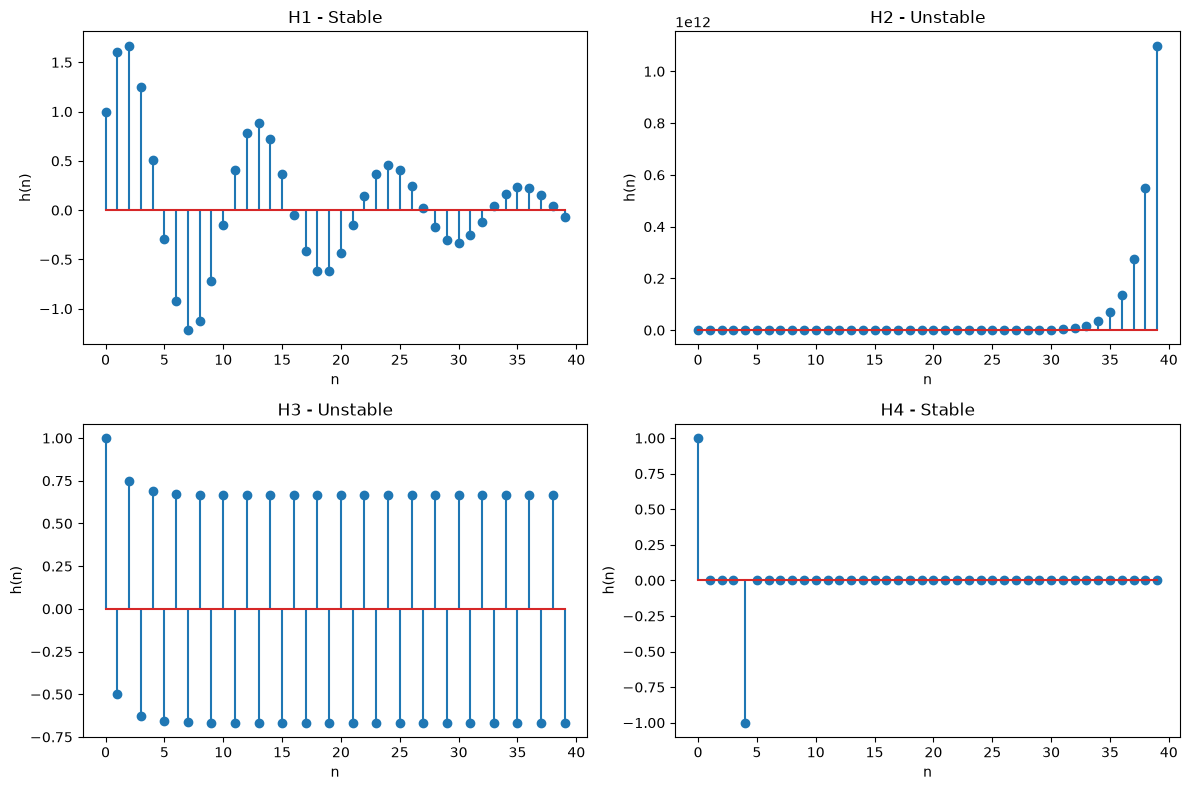

In [7]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

n = np.arange(40)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):

    z, p, k = signal.tf2zpk(b, a)

    stable = np.all(np.abs(p) < 1)

    impulse = np.zeros(40)
    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    ax.stem(n, h)
    ax.set_title(f"{name} - {'Stable' if stable else 'Unstable'}")
    ax.set_xlabel("n")
    ax.set_ylabel("h(n)")

    print(name)
    print("Poles:", p)
    print("Pole magnitudes:", np.abs(p))
    print("Stable:", stable)
    print("----------------------")

plt.tight_layout()
plt.show()

In [8]:
fs = 8000
f0 = 1000
r = 0.97

theta = 2 * np.pi * f0 / fs

b = [1, 0, -1]

a = [
    1,
    -2 * r * np.cos(theta),
    r**2
]

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

z, p, k = signal.tf2zpk(b, a)

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]
Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable: True


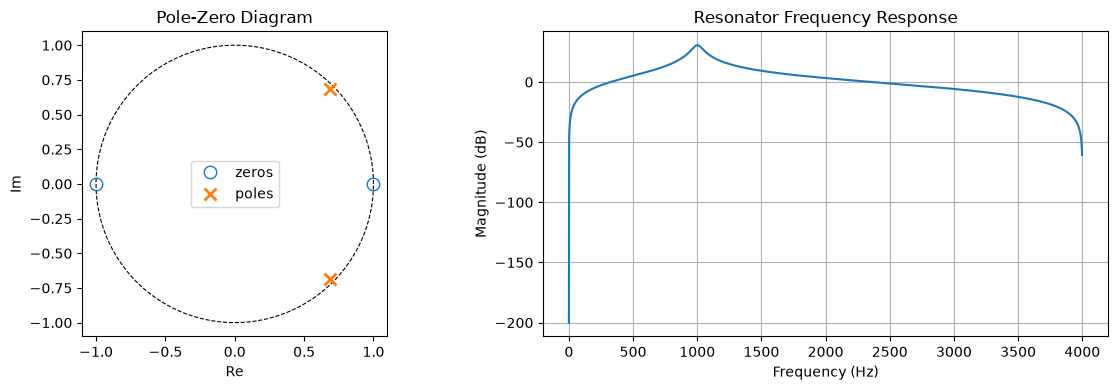

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Pole-Zero Plot
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-Zero Diagram")

# Frequency Response
w, H = signal.freqz(b, a, worN=2048)

frequency = w * fs / (2 * np.pi)

ax2.plot(frequency, 20 * np.log10(np.maximum(np.abs(H), 1e-10)))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

Input signal length: 16000
Output signal length: 16000


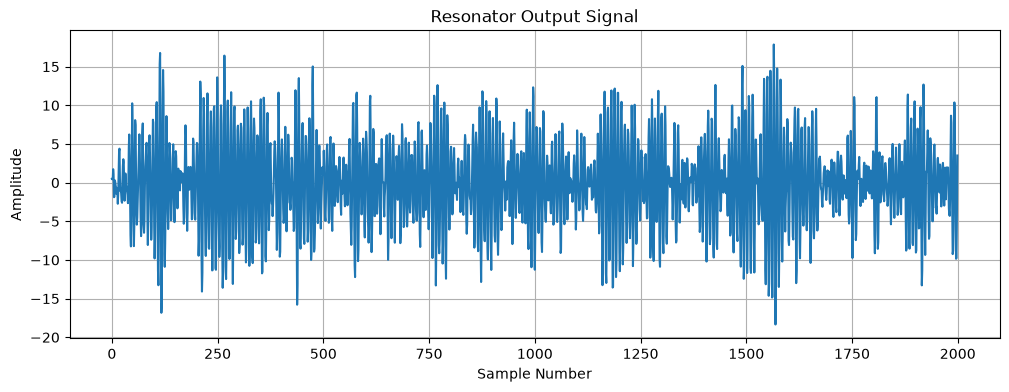

In [10]:
np.random.seed(42)

duration = 2

noise = np.random.randn(fs * duration)

y = signal.lfilter(b, a, noise)

print("Input signal length:", len(noise))
print("Output signal length:", len(y))

plt.figure(figsize=(12, 4))

plt.plot(y[:2000])

plt.title("Resonator Output Signal")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid()

plt.show()

## AI Use Statement

AI tools were used to assist in understanding Digital Signal Processing concepts, debugging Python code, interpreting simulation results, and improving the presentation of laboratory findings. All practical exercises were executed and verified by the student.